# Bussiness problem:

In [ ]:
# “Why do flight ticket prices vary so much? Which factors are associated with
# ticket fares, and how can we help customers make better flight-booking decisions?”

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymysql

In [3]:
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="12345",
    database="airline",
    port=3306
)

cur=conn.cursor()

In [4]:
query = "select * from `indian airlines`"
cur.execute(query)


300153

In [5]:
df = pd.read_sql_query(query , conn)

C:\Users\megha\AppData\Local\Temp\ipykernel_11100\1104816951.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query , conn)


In [8]:
df.drop("index" , axis = 1, inplace =True)

In [16]:
df.shape

(300153, 11)

In [17]:
df.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


In [19]:
df["airline"].unique()

array(['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo',
       'Air_India'], dtype=object)

In [20]:
df["flight"].unique()

array(['SG-8709', 'SG-8157', 'I5-764', ..., '6E-7127', '6E-7259',
       'AI-433'], shape=(1561,), dtype=object)

In [21]:
df["source_city"].unique()

array(['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai'],
      dtype=object)

In [22]:
df["destination_city"].unique()

array(['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi'],
      dtype=object)

In [23]:
df["departure_time"].unique()

array(['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night',
       'Late_Night'], dtype=object)

In [24]:
df["arrival_time"].unique()

array(['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening',
       'Late_Night'], dtype=object)

In [25]:
df["class"].unique()

array(['Economy', 'Business'], dtype=object)

In [26]:
df["stops"].unique()

array(['zero', 'one', 'two_or_more'], dtype=object)

In [27]:
df["duration"].nunique()

476

In [28]:
df.shape

(300153, 11)

In [29]:
df.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [30]:
df[df.duplicated()]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price


In [31]:
df.head(1)

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


In [33]:
categorical = []
numarical = []

In [34]:
for i in df.columns:
    if df[i].dtype == object :
        categorical.append(i)
    else:
        numarical.append(i)

In [35]:
categorical

['airline',
 'flight',
 'source_city',
 'departure_time',
 'stops',
 'arrival_time',
 'destination_city',
 'class']

In [36]:
numarical

['duration', 'days_left', 'price']

In [37]:
# EDA

In [38]:
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


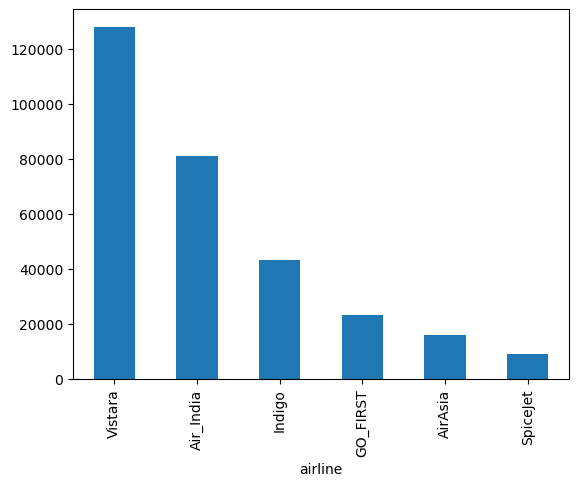

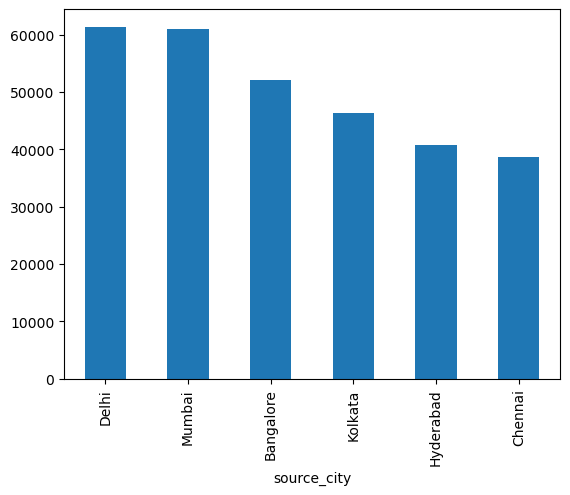

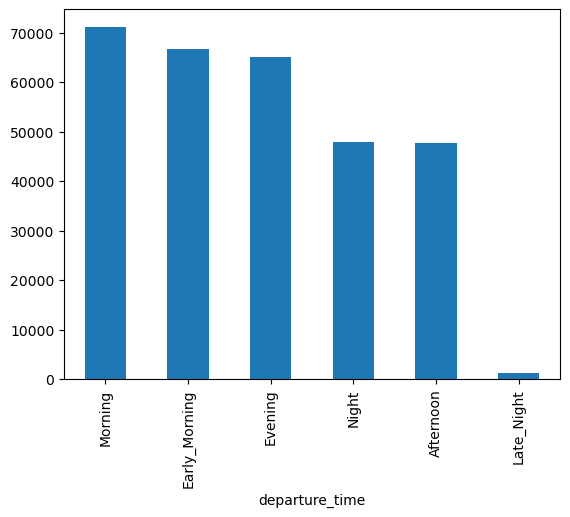

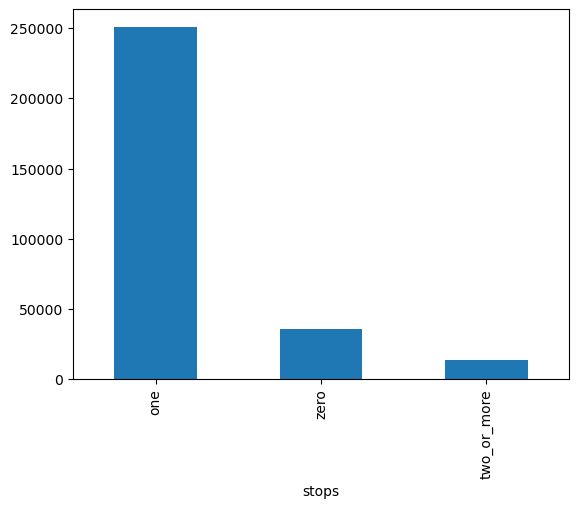

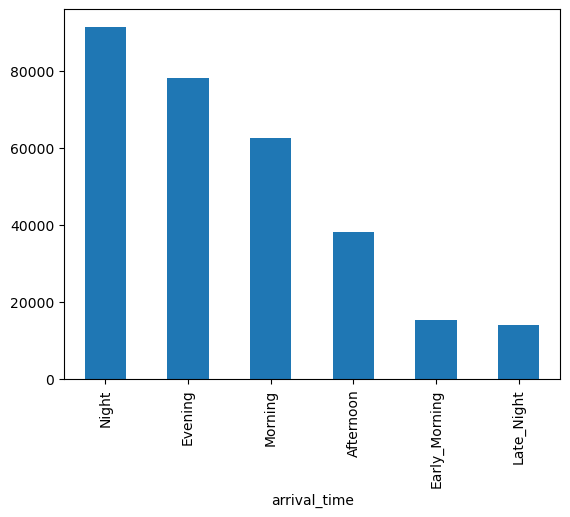

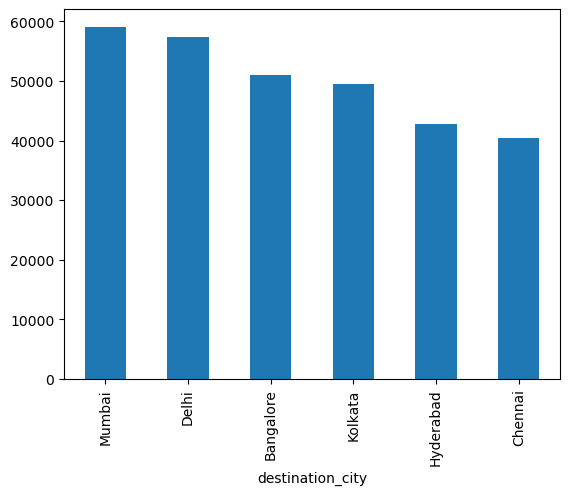

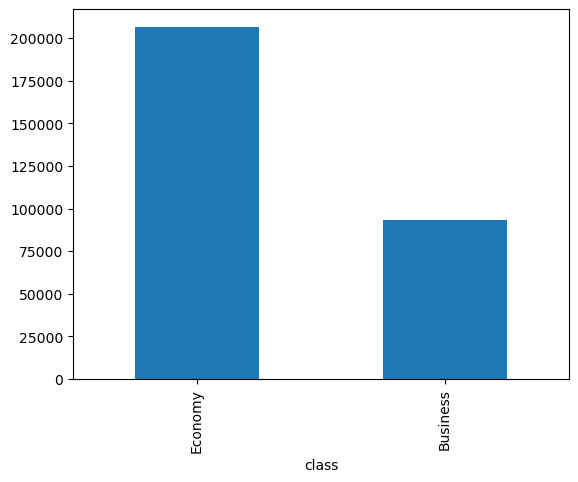

In [39]:
for i in categorical:
    if i != 'flight':
        df[i].value_counts().plot(kind= "bar")
        plt.show()

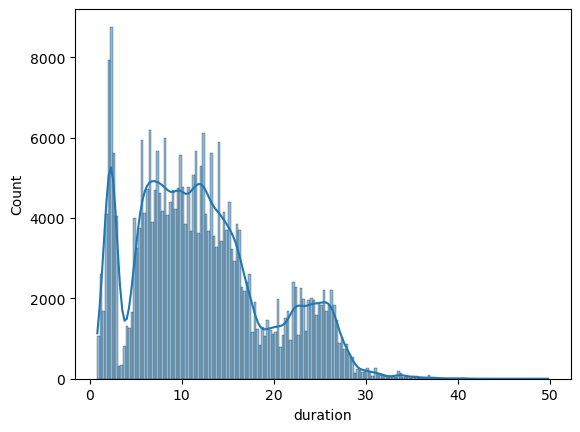

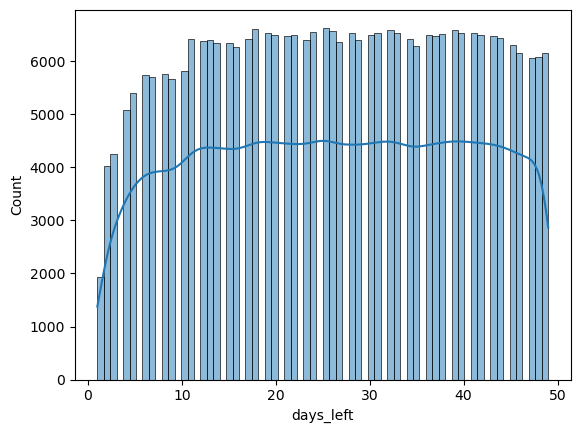

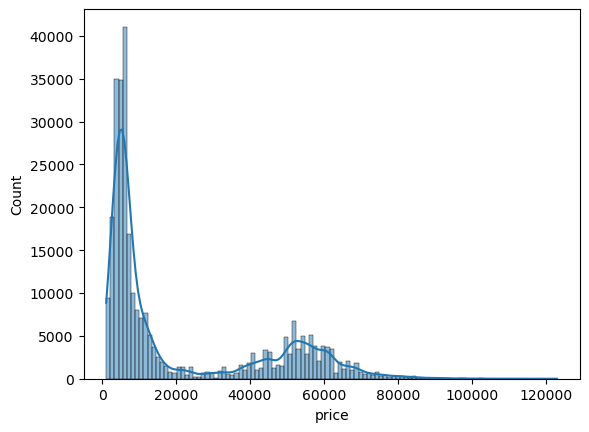

In [40]:
for i in numarical:
    sns.histplot(df[i], kde = True)
    plt.show()

In [41]:
# outliers 

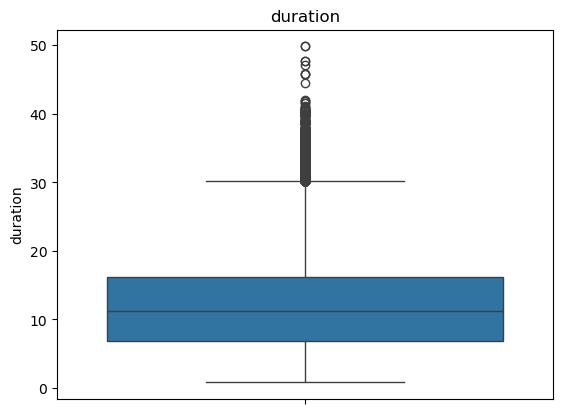

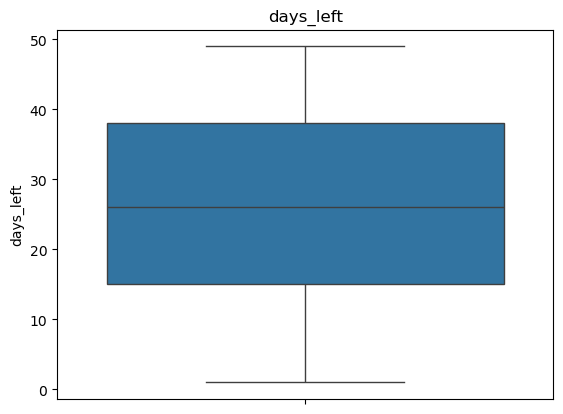

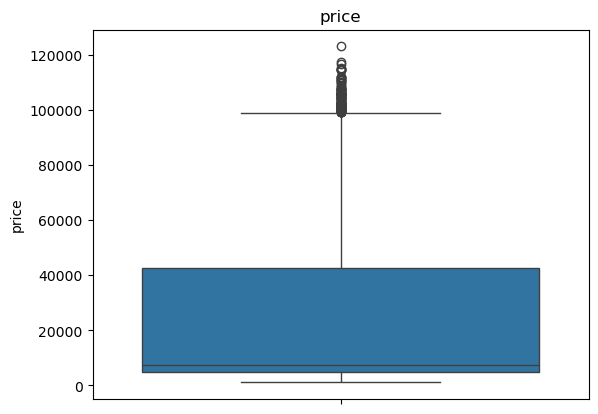

In [42]:
for i in numarical:
    sns.boxplot(df[i])
    plt.title(i)
    plt.show()

In [43]:
df["duration"].max()

49.83

In [44]:
df[df["duration"] > 48]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
193889,Air_India,AI-672,Chennai,Evening,two_or_more,Evening,Bangalore,Economy,49.83,2,23891
194359,Air_India,AI-672,Chennai,Evening,one,Evening,Bangalore,Economy,49.83,9,17538


# Pricing Analysis

In [45]:
# Different airlines ke ticket prices mein kitna difference hai

df["airline"].unique()

array(['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo',
       'Air_India'], dtype=object)

In [46]:
x=df.groupby("airline")["price"].mean().sort_values(ascending= False).index
y=df.groupby("airline")["price"].mean().sort_values(ascending= False).values


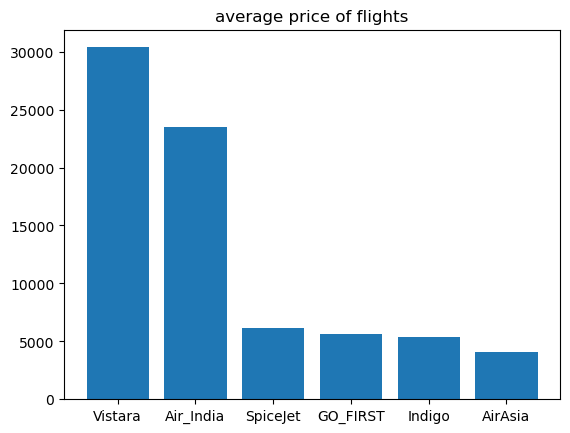

In [47]:
plt.bar(x,y)
plt.title("average price of flights")
plt.show()

In [48]:
#Business class ka fare Economy se kitna zyada hai?

In [49]:
df["class"].unique()

array(['Economy', 'Business'], dtype=object)

In [50]:
d=df.groupby("class")["price"].mean()
x=d.index
y = d.values

Text(0.5, 1.0, 'mean price diff between classes')

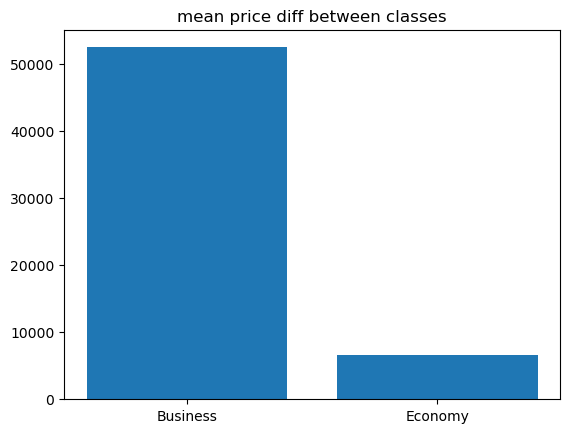

In [51]:
plt.bar(x,y)
plt.title("mean price diff between classes")

In [52]:
# Non-stop aur connecting flights ke fares mein kya difference hai?

In [53]:
df["stops"].unique()

array(['zero', 'one', 'two_or_more'], dtype=object)

In [54]:
d=df.groupby("stops")["price"].mean()
x = d.index
y = d.values

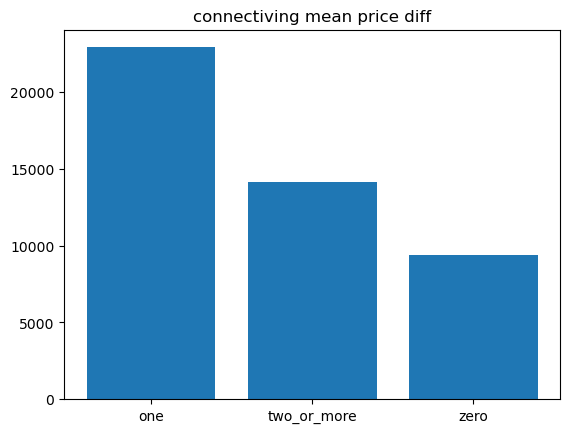

In [55]:
plt.bar(x,y)
plt.title("connectiving mean price diff")
plt.show()

In [56]:
# Kaunse routes par average fare sabse zyada hai?

In [57]:
df["route"] = df["source_city"] +" - "+ df["destination_city"]

In [58]:
df["route"].unique()

array(['Delhi - Mumbai', 'Delhi - Bangalore', 'Delhi - Kolkata',
       'Delhi - Hyderabad', 'Delhi - Chennai', 'Mumbai - Delhi',
       'Mumbai - Bangalore', 'Mumbai - Kolkata', 'Mumbai - Hyderabad',
       'Mumbai - Chennai', 'Bangalore - Delhi', 'Bangalore - Mumbai',
       'Bangalore - Kolkata', 'Bangalore - Hyderabad',
       'Bangalore - Chennai', 'Kolkata - Delhi', 'Kolkata - Mumbai',
       'Kolkata - Bangalore', 'Kolkata - Hyderabad', 'Kolkata - Chennai',
       'Hyderabad - Delhi', 'Hyderabad - Mumbai', 'Hyderabad - Bangalore',
       'Hyderabad - Kolkata', 'Hyderabad - Chennai', 'Chennai - Delhi',
       'Chennai - Mumbai', 'Chennai - Bangalore', 'Chennai - Kolkata',
       'Chennai - Hyderabad'], dtype=object)

In [59]:
d=df.groupby("route")["price"].mean().sort_values(ascending= False)
x = d.index
y = d.values

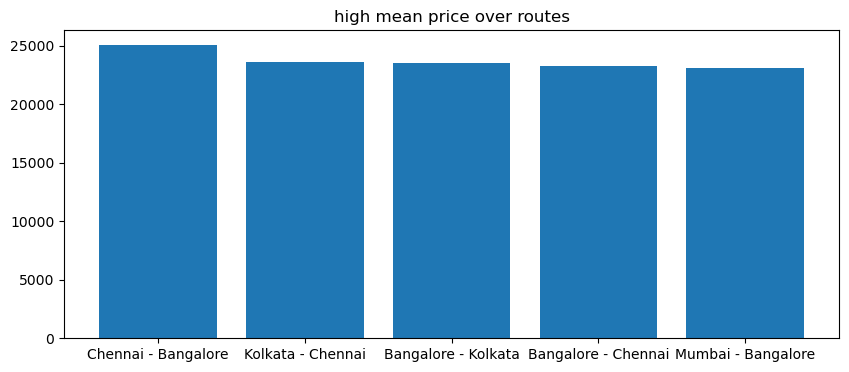

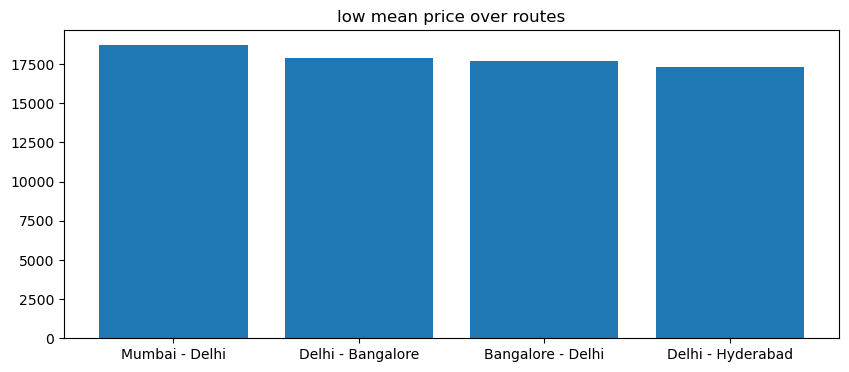

In [60]:
plt.figure(figsize=(10,4))
plt.bar(x[:5],y[:5])
plt.title("high mean price over routes")
plt.show()
plt.figure(figsize=(10,4))
plt.bar(x[-5:-1],y[-5:-1])
plt.title("low mean price over routes")
plt.show()

# Booking behaviours

In [61]:
#Departure se kitne din pehle booking karne par fares kam dikhte hain?

In [62]:
df.columns

Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left',
       'price', 'route'],
      dtype='object')

In [63]:
d=df.groupby("days_left")["price"].mean()
x= d.index
y = d.values

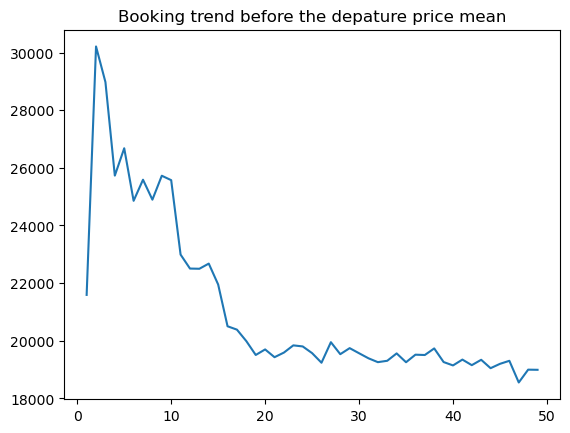

In [64]:
plt.plot(x,y)
plt.title("Booking trend before the depature price mean")
plt.show()

In [65]:
# Kya last-minute fares generally zyada hain?

# yes or no 

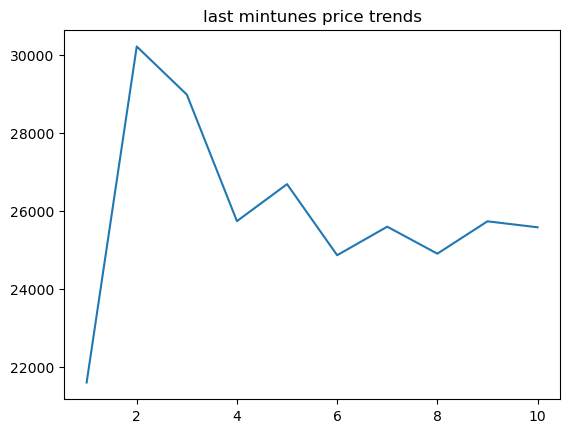

In [66]:
plt.plot(x[:10],y[:10])
plt.title("last mintunes price trends")
plt.show()

In [67]:
# Kya departure time ke hisaab se fares change hote hain?

In [68]:
d=df.groupby("departure_time")["price"].mean().sort_values(ascending= False)
x= d.index
y = d.values

Text(0.5, 1.0, 'mean price diff of departure time')

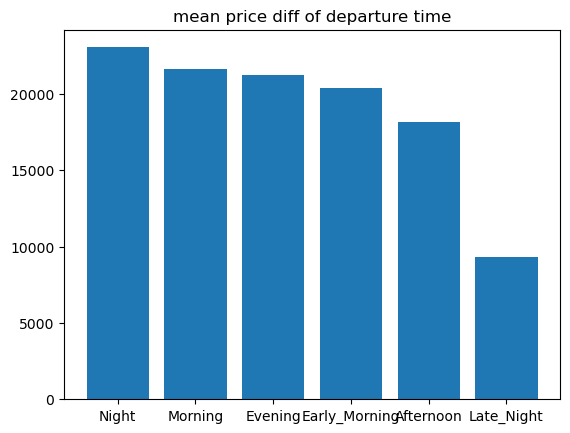

In [69]:
plt.bar(x,y)
plt.title("mean price diff of departure time")

# Flight Characteristics

In [70]:
# Kya longer-duration flights ke fares zyada hote hain? 

<Axes: xlabel='duration'>

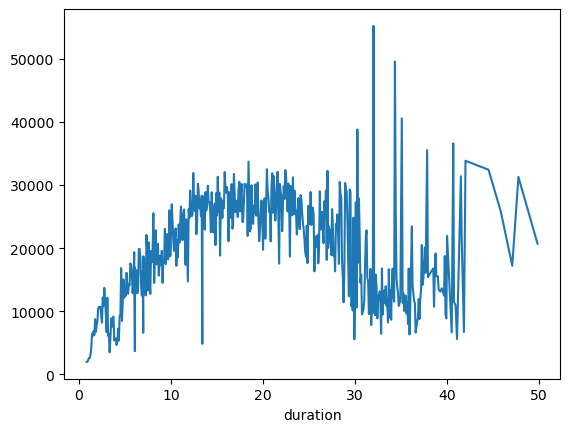

In [71]:
df.groupby('duration')["price"].mean().plot(kind = "line" )

In [72]:
# Kaunsi airlines comparable routes par relatively lower fares dikhati hain?

In [85]:
route =[]
price = []
airline = []
d=df.groupby(["route","airline"])["price"].mean().reset_index()
d
for i in df["route"].unique():
    s=d[d["route"]==i]
    mini = s[s["price"] == s["price"].min()]
    price.append(int(mini["price"]))
    airline.append(str(mini["airline"].values))
    
    route.append(str(mini["route"].values))
    
flight = pd.DataFrame({"route":route,"airline" : airline , "price" :price})
flight

C:\Users\megha\AppData\Local\Temp\ipykernel_11100\2962442202.py:9: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  price.append(int(mini["price"]))


,route,airline,price
0,['Delhi - Mumbai'],['AirAsia'],3981
1,['Delhi - Bangalore'],['AirAsia'],5316
2,['Delhi - Kolkata'],['AirAsia'],4160
3,['Delhi - Hyderabad'],['AirAsia'],4733
4,['Delhi - Chennai'],['AirAsia'],3393
5,['Mumbai - Delhi'],['Indigo'],3935
6,['Mumbai - Bangalore'],['AirAsia'],3580
7,['Mumbai - Kolkata'],['AirAsia'],3977
8,['Mumbai - Hyderabad'],['AirAsia'],3068
9,['Mumbai - Chennai'],['AirAsia'],2909


In [74]:
# Kya stops aur duration ko control karne ke baad bhi airline-wise price differences hain?

# Advanced Statistical Questions

In [ ]:
# Kya airlines ke average fares mein statistically significant difference hai?

In [66]:
import scipy.stats as ss

In [67]:
g1 = df[df["airline"]== 'SpiceJet']["price"]
g2 = df[df["airline"]== 'Indigo']["price"]
g3 = df[df["airline"]== 'GO_FIRST']["price"]
g4 = df[df["airline"]== 'Vistara']["price"]
g5 = df[df["airline"]== 'AirAsia']["price"]
g6 = df[df["airline"] == 'Air_India']["price"]

In [68]:
f,p=ss.f_oneway(g1,g2,g3,g4,g5,g6)
if p < 0.05:
    print("There is a statistically significant difference in average fares.")
else:
    print("There is insufficient evidence of a statistically significant difference in average fares.")

There is a statistically significant difference in average fares.


In [69]:
df["class"].unique()

array(['Economy', 'Business'], dtype=object)

In [70]:
# Kya class aur airline ka fare par combined effect hai?

In [71]:
g1=df[df["class"]=="Economy"]["price"]
g2 = df[df["class"]=='Business']["price"]

f , p = ss.f_oneway(g1 , g2)
if p < 0.05:
    print("There is a statistically significant difference in average fares.")
else:
    print("There is insufficient evidence of a statistically significant difference in average fares.")

There is a statistically significant difference in average fares.


In [72]:
# Price kin variables ke saath sabse strongly associated hai?

<Axes: >

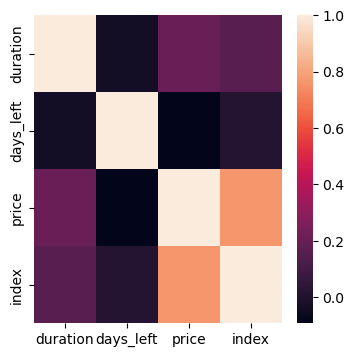

In [73]:
plt.figure(figsize=(4,4))
sns.heatmap(df[numarical].corr())

In [74]:
# chi Sqaure test

In [75]:
s= categorical

In [76]:
s.remove("flight")

In [77]:
c=1
for i in range(len(s)):
    
    for j in range( i+1 ,len(s)):
        o = pd.crosstab(df[s[i]],df[s[j]])
        f , p , d , e=ss.chi2_contingency(o)
    
        if p < 0.05:
            print(s[i] , s[j] ,  p ,c)
            c+=1

airline source_city 0.0 1
airline departure_time 0.0 2
airline stops 0.0 3
airline arrival_time 0.0 4
airline destination_city 0.0 5
airline class 0.0 6
source_city departure_time 0.0 7
source_city stops 0.0 8
source_city arrival_time 0.0 9
source_city destination_city 0.0 10
source_city class 5.049342709943103e-49 11
departure_time stops 0.0 12
departure_time arrival_time 0.0 13
departure_time destination_city 0.0 14
departure_time class 0.0 15
stops arrival_time 0.0 16
stops destination_city 0.0 17
stops class 0.0 18
arrival_time destination_city 0.0 19
arrival_time class 0.0 20
destination_city class 6.408771472142409e-50 21


In [30]:
# Kaunse observations unusual fares dikhate hain, aur kya woh genuine hain?

<Axes: ylabel='price'>

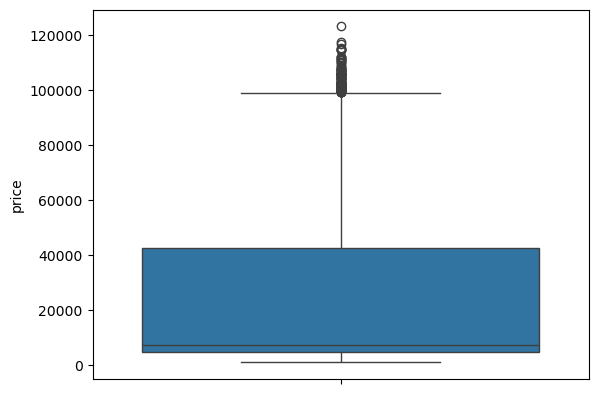

In [78]:
sns.boxplot(df["price"])

In [79]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1


In [80]:
lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr

In [81]:
lower , upper

(np.float64(-51824.0), np.float64(99128.0))

In [82]:
print("outlier count of fares :- " ,len(df[(df["price"] < lower) | (df["price"] > upper)]))

outlier count of fares :-  123
